# Background

- **Author**: Codex
- **Created At**: 2026-10-13
- **Research Motivation and Context (why are we interested in the findings?)：** 這次把假訂單、商品類別和日期資訊合併，練習用 Plotly 觀察金額分布、不同類別的銷售額與每日變化。資料讀自 `data/processed/demo_orders_clean.csv`，共 115 筆，清理方式見 [整理後資料說明](../data/processed/demo_orders_documentation.ipynb)。這裡使用全部整理後的資料。
- **Main Findings and Takeaways：** 三表合併後仍為 115 筆，共 9 欄。總金額 62,071 元，平均每筆 539.75 元，中位數 485 元。飲品的樣本銷售額最高，為 21,391 元；每日總額介於 626 元與 4,405 元。
- **Future Direction：** 若改用真實資料，可以延長觀察期間，再確認每日訂單組成、假日與促銷資訊是否足以解釋變化。

資料是人工生成的，以下結果只用來練習分析與表格呈現。

第一次執行時，先用 `python data/code/demo_generate_orders.py` 產生原始資料，再執行 [處理 notebook](../data/code/demo_orders_processing.ipynb)。使用 pandas 和 Plotly；PNG 匯出另外需要 kaleido 與 Chrome。圖片會存到 `finding/assets/demo_orders_analysis/`。

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 找到專案資料夾，從不同位置開啟 notebook 都能讀到資料。
project_root = Path.cwd().resolve()
while not ((project_root / "AGENTS.md").is_file() and (project_root / "templates").is_dir()):
    if project_root == project_root.parent:
        raise FileNotFoundError("請從專案資料夾內開啟 notebook。")
    project_root = project_root.parent

import plotly.express as px
import plotly.io as pio

pio.templates.default = "plotly_white"
# 互動圖供 Jupyter／VS Code 使用，PNG 輸出供靜態預覽。
pio.renderers.default = "plotly_mimetype+png"
px.defaults.width = 960
px.defaults.height = 520
figure_dir = project_root / "finding/assets/demo_orders_analysis"
figure_dir.mkdir(parents=True, exist_ok=True)


In [2]:
df = pd.read_csv(project_root / "data/processed/demo_orders_clean.csv")
assert df["order_id"].is_unique
assert not df.isna().any().any()
print(f"這次分析使用 {len(df)} 筆訂單。以下是前 10 筆：")
display(df.head(10))


這次分析使用 115 筆訂單。以下是前 10 筆：


,order_id,order_date,category,quantity,unit_price_twd,order_amount_twd,category_name,weekday,day_type
0,D0001,2026-09-01,A,1,80,80,飲品,星期二,平日
1,D0002,2026-09-02,B,3,97,291,點心,星期三,平日
2,D0003,2026-09-03,C,5,114,570,輕食,星期四,平日
3,D0004,2026-09-04,A,2,131,262,飲品,星期五,平日
4,D0005,2026-09-05,B,4,148,592,點心,星期六,週末
5,D0006,2026-09-06,C,1,165,165,輕食,星期日,週末
6,D0007,2026-09-07,A,3,182,546,飲品,星期一,平日
7,D0008,2026-09-08,B,5,199,995,點心,星期二,平日
8,D0010,2026-09-10,A,4,233,932,飲品,星期四,平日
9,D0011,2026-09-11,B,1,250,250,點心,星期五,平日


In [3]:
# 先看金額與件數，再整理圖表會用到的商品類別及日期。
variable_names = {
    "quantity": "購買件數（件）",
    "unit_price_twd": "每件單價（新臺幣元）",
    "order_amount_twd": "訂單金額（新臺幣元）",
}
stat_names = {
    "count": "有效 N",
    "mean": "平均",
    "std": "標準差",
    "min": "最小值",
    "25%": "第25百分位",
    "50%": "中位數",
    "75%": "第75百分位",
    "max": "最大值",
    "missing_n": "缺值 N",
}

numeric_data = df[list(variable_names)]
summary = numeric_data.describe(percentiles=[0.25, 0.5, 0.75]).T
summary["missing_n"] = numeric_data.isna().sum()
summary = summary.rename(index=variable_names, columns=stat_names)

print(f"表 1：分析變數敘述統計（N={len(df)}；有效 N 為非缺值筆數）")
display(summary.round(2))

category_counts = df["category"].value_counts().sort_index()
category_table = category_counts.to_frame("筆數")
category_table.index.name = "商品類別"
category_table["百分比"] = category_counts / df["category"].notna().sum() * 100

print(f"表 2：商品類別分布（N={len(df)}）")
print(f"百分比以全部非缺值訂單為分母；類別缺值 {df['category'].isna().sum()} 筆。")
display(category_table.round(2))

for column, label in [("category_name", "商品類別名稱"), ("day_type", "平日／週末"), ("order_date", "訂單日期")]:
    counts = df[column].value_counts().head(10)
    table = counts.to_frame("筆數")
    table["百分比"] = table["筆數"] / df[column].notna().sum() * 100
    print(f"{label}（N={len(df)}；最多顯示前 10 類，百分比分母為所有非缺值訂單）")
    print(f"缺值：{df[column].isna().sum()} 筆")
    display(table.round(2))
print(f"日期範圍：{df['order_date'].min()} 至 {df['order_date'].max()}，共 {df['order_date'].nunique()} 天。")


表 1：分析變數敘述統計（N=115；有效 N 為非缺值筆數）


,有效 N,平均,標準差,最小值,第25百分位,中位數,第75百分位,最大值,缺值 N
購買件數（件）,115.0,3.01,1.44,1.0,2.0,3.0,4.0,5.0,0
每件單價（新臺幣元）,115.0,179.19,64.83,80.0,122.5,182.0,233.0,284.0,0
訂單金額（新臺幣元）,115.0,539.75,337.45,80.0,262.0,485.0,750.0,1420.0,0


表 2：商品類別分布（N=115）
百分比以全部非缺值訂單為分母；類別缺值 0 筆。


,筆數,百分比
商品類別,,
A,39,33.91
B,37,32.17
C,39,33.91


商品類別名稱（N=115；最多顯示前 10 類，百分比分母為所有非缺值訂單）
缺值：0 筆


...

平日／週末（N=115；最多顯示前 10 類，百分比分母為所有非缺值訂單）
缺值：0 筆


,筆數,百分比
day_type,,
平日,86,74.78
週末,29,25.22


訂單日期（N=115；最多顯示前 10 類，百分比分母為所有非缺值訂單）
缺值：0 筆


,筆數,百分比
order_date,,
2026-09-01,4,3.48
2026-09-16,4,3.48
2026-09-30,4,3.48
2026-09-28,4,3.48
2026-09-27,4,3.48
2026-09-26,4,3.48
2026-09-25,4,3.48
2026-09-24,4,3.48
2026-09-23,4,3.48


日期範圍：2026-09-01 至 2026-09-30，共 30 天。


### The actual analysis starts below

以下用 Plotly 畫四張 EDA 圖，依序看金額分布、商品類別、每日變化及購買件數。圖表使用全部 115 筆合併後的訂單；合併與清理已在 data/code 完成。

In [4]:
total_amount = df["order_amount_twd"].sum()
average_amount = df["order_amount_twd"].mean()
print(f"總金額：{total_amount:,} 元")
print(f"平均每筆：{average_amount:,.2f} 元")

summary_export = summary.rename_axis("變數").reset_index()
output_path = project_root / "finding/demo_orders_summary.csv"
summary_export.to_csv(output_path, index=False)
print("摘要表已存到 finding/demo_orders_summary.csv")


總金額：62,071 元
平均每筆：539.75 元
摘要表已存到 finding/demo_orders_summary.csv


平均訂單金額為 539.75 元，比中位數 485 元高約 54.75 元，表示金額較高的訂單把平均值往上拉。金額的標準差約為 337.45 元，最小值為 80 元，最大值為 1,420 元，訂單之間仍有明顯差異。

A、B、C 三類的訂單占比分別約為 33.91%、32.17%、33.91%。這裡只是描述這份資料的組成，沒有比較各類別的消費差異，也沒有做因果推論。

### 1. 訂單金額分布

將金額每 100 元分成一組，查看 115 筆訂單集中在哪些區間。這裡畫的是各區間的實際訂單數。

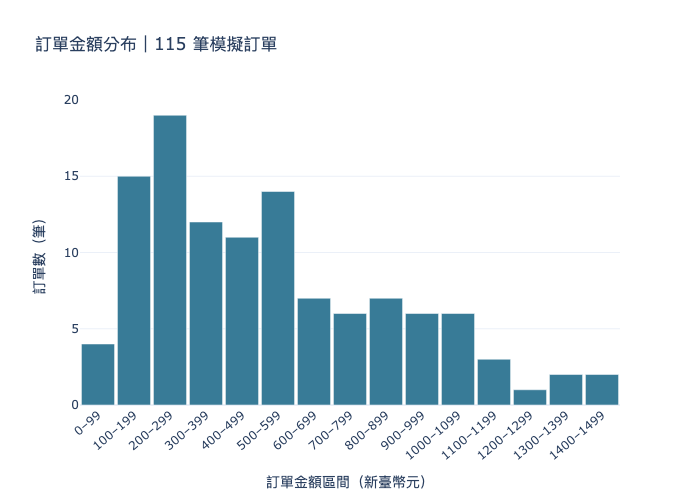

In [5]:
# 先彙整成區間筆數，互動圖只保留分布摘要。
bins = list(range(0, 1501, 100))
amount_groups = pd.cut(df["order_amount_twd"], bins=bins, right=False)
amount_counts = amount_groups.value_counts(sort=False)
distribution = pd.DataFrame({
    "金額區間": [f"{int(interval.left)}–{int(interval.right)-1}" for interval in amount_counts.index],
    "訂單數": amount_counts.values,
})
fig = px.bar(distribution, x="金額區間", y="訂單數",
             title="訂單金額分布｜115 筆模擬訂單", color_discrete_sequence=["#387B97"])
fig.update_layout(xaxis_title="訂單金額區間（新臺幣元）", yaxis_title="訂單數（筆）", bargap=0.08)
fig.update_xaxes(tickangle=-40)
fig.write_image(figure_dir / "01_amount_distribution.png", scale=2)
fig.show()


### 2. 各商品類別的銷售額

把訂單金額依商品名稱加總。飲品為 21,391 元，輕食為 20,983 元，點心為 19,697 元，三類的總額相差不大。這裡呈現的是銷售額，還沒有考慮成本或利潤。

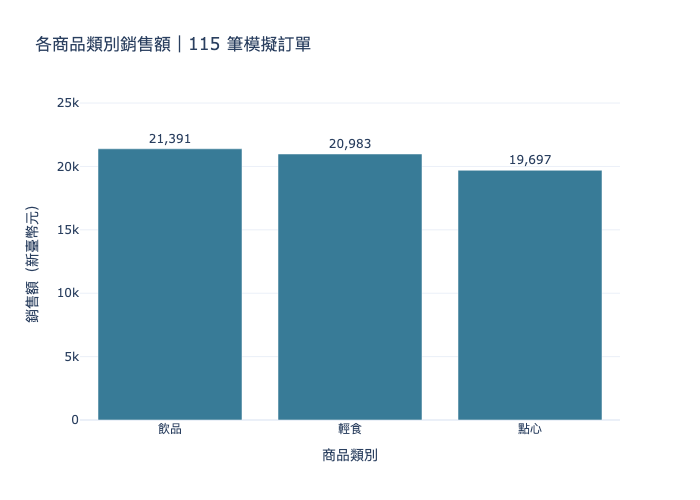

In [6]:
category_sales = df.groupby("category_name", as_index=False).agg(
    sales=("order_amount_twd", "sum"),
    orders=("order_id", "count"),
).sort_values("sales", ascending=False)
fig = px.bar(category_sales, x="category_name", y="sales", text="sales",
             hover_data={"orders": True},
             labels={"category_name": "商品類別", "sales": "銷售額（新臺幣元）", "orders": "訂單數"},
             title="各商品類別銷售額｜115 筆模擬訂單", color_discrete_sequence=["#387B97"])
fig.update_traces(texttemplate="%{text:,.0f}", textposition="outside", cliponaxis=False)
fig.update_layout(yaxis_range=[0, category_sales["sales"].max() * 1.18])
fig.write_image(figure_dir / "02_category_sales.png", scale=2)
fig.show()


### 3. 每日銷售額

將每天的訂單金額加總，橘色點表示週末。9 月 13 日最高，為 4,405 元；9 月 6 日最低，為 626 元。

每天的訂單數、件數和單價都可能不同，所以不能只看這張圖就說週末賣得比較好。

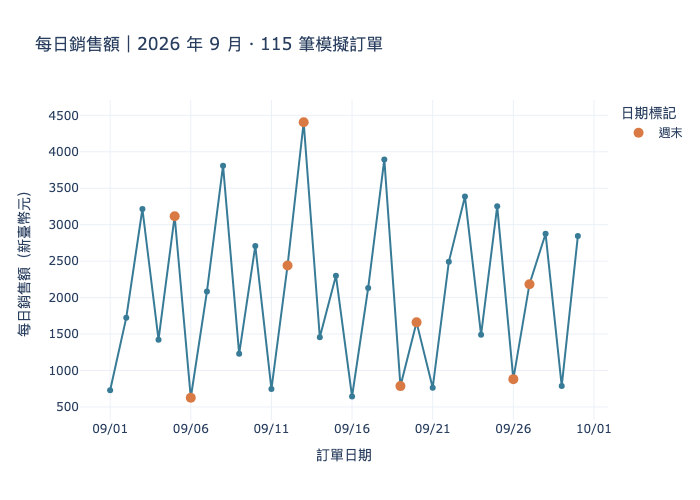

In [7]:
daily_sales = df.groupby(["order_date", "day_type"], as_index=False).agg(
    sales=("order_amount_twd", "sum"),
    orders=("order_id", "count"),
).sort_values("order_date")
daily_sales["order_date"] = pd.to_datetime(daily_sales["order_date"])
fig = px.line(daily_sales, x="order_date", y="sales", markers=True,
              hover_data={"day_type": True, "orders": True},
              labels={"order_date": "訂單日期", "sales": "每日銷售額（新臺幣元）", "day_type": "日期類型", "orders": "訂單數"},
              title="每日銷售額｜2026 年 9 月・115 筆模擬訂單")
fig.update_traces(line_color="#387B97", name="每日銷售額")
weekends = daily_sales.loc[daily_sales["day_type"] == "週末"]
fig.add_scatter(x=weekends["order_date"], y=weekends["sales"], mode="markers", name="週末",
                marker={"color": "#D97A45", "size": 10},
                hovertemplate="%{x|%m/%d}（週末）<br>銷售額：%{y:,.0f} 元<extra></extra>")
fig.update_xaxes(dtick=5 * 24 * 60 * 60 * 1000, tickformat="%m/%d")
fig.update_layout(hovermode="x unified", legend_title_text="日期標記")
fig.write_image(figure_dir / "03_daily_sales.png", scale=2)
fig.show()


### 4. 購買件數與訂單金額

每個點是一筆訂單，顏色區分商品類別。件數相同時，金額仍有差異，主要是因為單價不同；件數增加時，金額的分布範圍也變大。

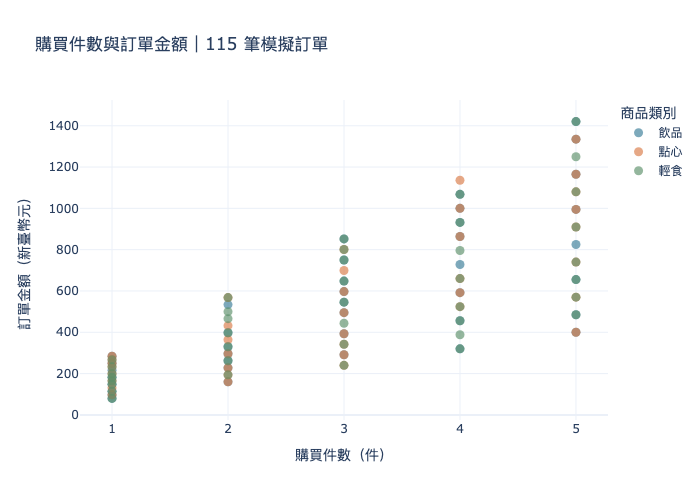

In [8]:
fig = px.scatter(df, x="quantity", y="order_amount_twd", color="category_name", opacity=0.65,
                 labels={"quantity": "購買件數（件）", "order_amount_twd": "訂單金額（新臺幣元）", "category_name": "商品類別"},
                 title="購買件數與訂單金額｜115 筆模擬訂單",
                 color_discrete_map={"飲品": "#387B97", "點心": "#D97A45", "輕食": "#5B8F68"})
fig.update_traces(marker_size=9)
fig.update_xaxes(dtick=1)
fig.write_image(figure_dir / "04_quantity_amount.png", scale=2)
fig.show()


件數相同的訂單仍有不同金額，因為單價不同。件數與金額的關係也直接來自「金額＝件數 × 單價」這個定義，不能解讀成另外估計出的因果效果。日期與類別是用固定規則生成，圖中的規律不代表真實市場現象。